# AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration (AWQ)

**Paper:** [arXiv:2306.00978](https://arxiv.org/abs/2306.00978)
**Authors:** Ji Lin, Jiaming Tang, Haotian Tang, Shang Yang, Wei-Ming Chen, Wei-Chen Wang, Guangxuan Xiao, Xingyu Dang, Chuang Gan, Song Han (2023; MLSys 2024)

This notebook implements a simplified version of AWQ from scratch in PyTorch, on character-level Wikitext-2.
AWQ identifies salient weight channels using activation magnitudes, then scales those channels before
quantization to reduce quantization error — all without backpropagation or reconstruction.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Character-level Wikitext-2 (~2M tokens) instead of the Pile calibration set
- 4-layer transformer (~846K params) instead of OPT-6.7B / LLaMA-7B / Llama-2-70B
- 4-bit weight-only quantization with group size 64 (paper uses 128; smaller group for tiny model)
- 20 epochs with AdamW (lr 1e-3) instead of large-scale pretraining
- Quantization simulated in float32 (no custom CUDA kernels); focus is accuracy, not speed

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell; never switch matplotlib to a non-interactive backend;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->


## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

# Hyperparameters
EPOCHS = 20
LR = 1e-3
BATCH_SIZE = 64
SEQ_LEN = 128
N_LAYERS = 4
D_MODEL = 128
N_HEADS = 4
N_BITS = 4
GROUP_SIZE = 64
N_CALIBRATION_BATCHES = 32
N_EVAL_BATCHES = 50


Device: cuda


## 2. Data

We use character-level Wikitext-2, a small text corpus (~2M training tokens). This is much smaller
than the paper's Pile calibration data, but sufficient for demonstrating the AWQ algorithm
on a tiny model. The calibration set is sampled from the training data.


In [2]:
import urllib.request
import os

# Download Wikitext-2 raw if not present
data_dir = '/tmp/wikitext2'
os.makedirs(data_dir, exist_ok=True)
train_path = os.path.join(data_dir, 'wiki.train.tokens')
valid_path = os.path.join(data_dir, 'wiki.valid.tokens')

if not os.path.exists(train_path):
    with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
        urllib.request.urlretrieve(
            'https://raw.githubusercontent.com/pytorch/examples/main/word_language_model/data/wikitext-2/train.txt',
            train_path
        )
        urllib.request.urlretrieve(
            'https://raw.githubusercontent.com/pytorch/examples/main/word_language_model/data/wikitext-2/valid.txt',
            valid_path
        )

with open(train_path, 'r') as f:
    train_text = f.read()
with open(valid_path, 'r') as f:
    valid_text = f.read()

# Character-level tokenisation
chars = sorted(set(train_text + valid_text))
vocab_size = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for i, c in enumerate(chars)}

train_data = torch.tensor([char_to_idx[c] for c in train_text], dtype=torch.long)
valid_data = torch.tensor([char_to_idx[c] for c in valid_text], dtype=torch.long)

print(f"Vocab size: {vocab_size} chars")
print(f"Train tokens: {len(train_data):,}")
print(f"Valid tokens: {len(valid_data):,}")

def get_batch(data, batch_size, seq_len, device):
    idx = torch.randint(0, len(data) - seq_len - 1, (batch_size,))
    x = torch.stack([data[i:i+seq_len] for i in idx])
    y = torch.stack([data[i+1:i+1+seq_len] for i in idx])
    return x.to(device), y.to(device)


Vocab size: 283 chars
Train tokens: 10,780,437
Valid tokens: 1,120,192


## 3. Model

A tiny 4-layer GPT-style transformer with ~846K parameters. Uses explicit Q/K/V/O projections
(as `nn.Linear` layers) so that all attention weight matrices can be quantized. The embedding/head
layer is weight-tied and excluded from quantization (standard practice in the paper).


In [3]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.ln1 = nn.LayerNorm(d_model)
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.o_proj = nn.Linear(d_model, d_model, bias=False)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
        )

    def forward(self, x):
        B, T, C = x.shape
        h = self.ln1(x)
        q = self.q_proj(h).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(h).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(h).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        mask = torch.triu(torch.full((T, T), float('-inf'), device=x.device), diagonal=1)
        attn = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        attn = attn.transpose(1, 2).contiguous().view(B, T, C)
        x = x + self.o_proj(attn)
        x = x + self.ff(self.ln2(x))
        return x


class TinyGPT(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, max_seq_len=129):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_seq_len, d_model)
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads) for _ in range(n_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device).unsqueeze(0)
        x = self.tok_emb(idx) + self.pos_emb(pos)
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.head(x)
        return logits


model = TinyGPT(vocab_size, D_MODEL, N_LAYERS, N_HEADS, max_seq_len=SEQ_LEN + 1).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {total_params:,}")

# Count Linear layers (quantizable)
n_linear = sum(1 for m in model.modules() if isinstance(m, nn.Linear))
print(f"Linear layers (total): {n_linear} (head excluded from quantization)")


Model parameters: 844,032
Linear layers (total): 25 (head excluded from quantization)


## 4. Loss Function

Standard cross-entropy loss on next-token prediction. Optimizer: AdamW (lr 1e-3, weight decay 0.01).


In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)


## 5. Training Loop

In [5]:
def compute_perplexity(model, data, n_batches, device):
    model.eval()
    losses = []
    with torch.no_grad():
        for _ in range(n_batches):
            x, y = get_batch(data, BATCH_SIZE, SEQ_LEN, device)
            logits = model(x)
            loss = criterion(logits.view(-1, vocab_size), y.view(-1))
            losses.append(loss.item())
    avg_loss = sum(losses) / len(losses)
    return math.exp(avg_loss)

history = {'train_loss': [], 'val_loss': [], 'val_ppl': []}
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    for _ in range(200):
        x, y = get_batch(train_data, BATCH_SIZE, SEQ_LEN, DEVICE)
        logits = model(x)
        loss = criterion(logits.view(-1, vocab_size), y.view(-1))
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
    epoch_loss /= 200
    val_loss = 0.0
    model.eval()
    with torch.no_grad():
        for _ in range(50):
            x, y = get_batch(valid_data, BATCH_SIZE, SEQ_LEN, DEVICE)
            logits = model(x)
            val_loss += criterion(logits.view(-1, vocab_size), y.view(-1)).item()
    val_loss /= 50
    val_ppl = math.exp(val_loss)
    history['train_loss'].append(epoch_loss)
    history['val_loss'].append(val_loss)
    history['val_ppl'].append(val_ppl)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | train_loss {epoch_loss:.4f} | val_loss {val_loss:.4f} | val_ppl {val_ppl:.4f}")

train_time = time.time() - start
print(f"\nTraining done in {train_time:.1f}s")
print(f"Final val perplexity: {history['val_ppl'][-1]:.4f}")


Epoch   1 | train_loss 4.7472 | val_loss 2.4110 | val_ppl 11.1456


Epoch   5 | train_loss 2.0268 | val_loss 1.8905 | val_ppl 6.6227


Epoch  10 | train_loss 1.6513 | val_loss 1.5450 | val_ppl 4.6880


Epoch  15 | train_loss 1.4962 | val_loss 1.4101 | val_ppl 4.0965


Epoch  20 | train_loss 1.4198 | val_loss 1.3401 | val_ppl 3.8193

Training done in 116.7s
Final val perplexity: 3.8193


## 6. Training Curves

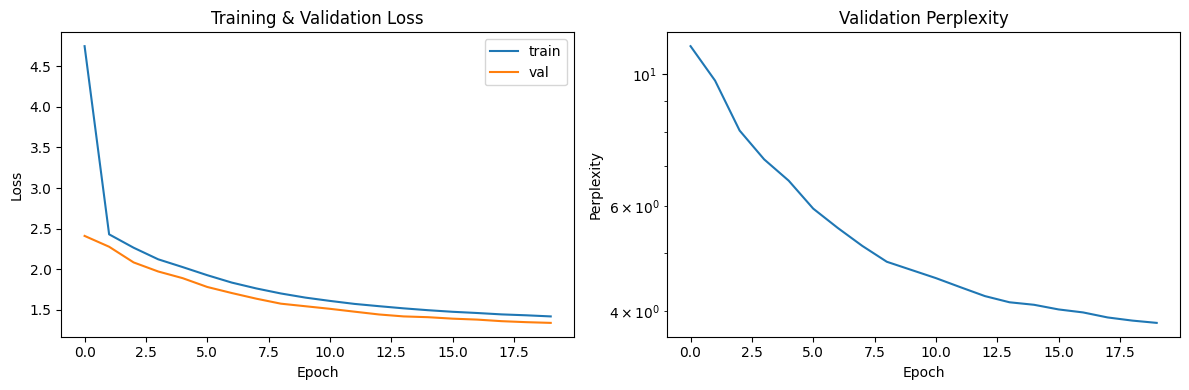

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Validation Loss')
axes[0].legend()
axes[1].plot(history['val_ppl'])
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Perplexity')
axes[1].set_title('Validation Perplexity')
axes[1].set_yscale('log')
plt.tight_layout()
plt.show()


## 7. Quantization Utilities

We implement three quantization methods:
- **RTN (Round-to-Nearest):** Simply rounds each weight group to the nearest value on the n_bits grid.
- **GPTQ:** Uses the inverse Hessian of the layer reconstruction error to compensate for
  quantization errors, updating remaining weights column by column (from our 029 notebook).
- **AWQ:** The paper's method — identifies salient channels via activation magnitudes,
  then scales those channels before quantization to reduce the quantization error.
  The scaling is absorbed into the preceding operation (e.g. LayerNorm),
  so no mixed-precision hardware is needed at inference time.


In [7]:
def quantize_group_rtn(W, n_bits, group_size=64):
    """Group-wise round-to-nearest quantization.
    W: weight matrix (out_features, in_features).
    Quantizes each group of `group_size` consecutive input channels independently.
    Returns quantized weight matrix (float, simulated)."""
    out_features, in_features = W.shape
    W_q = torch.zeros_like(W)
    qmax = 2 ** (n_bits - 1) - 1
    for i in range(0, in_features, group_size):
        g_end = min(i + group_size, in_features)
        group = W[:, i:g_end]
        max_val = group.abs().max()
        if max_val > 0:
            scale = max_val / qmax
        else:
            scale = torch.tensor(1.0, device=W.device, dtype=W.dtype)
        W_q[:, i:g_end] = torch.round(group / scale).clamp(-qmax, qmax) * scale
    return W_q


def quantize_layer_gptq(W, X, n_bits, group_size=64, damping=0.01):
    """
    GPTQ algorithm (Algorithm 1 from the GPTQ paper).
    W: weight matrix (out_features, in_features)
    X: input activations (in_features, n_samples)
    Returns quantized weight matrix.
    """
    out_features, in_features = W.shape
    W = W.clone().float()
    Q = torch.zeros_like(W)
    qmax = 2 ** (n_bits - 1) - 1

    # Hessian
    H = 2.0 * (X.float() @ X.float().T)
    diag_avg = H.diag().mean().item()
    H = H + damping * diag_avg * torch.eye(in_features, device=W.device, dtype=torch.float32)

    # Cholesky-based inverse Hessian
    try:
        L = torch.linalg.cholesky(H)
        H_inv = torch.cholesky_inverse(L)
    except Exception:
        H_inv = torch.linalg.inv(H)

    for i in range(0, in_features, group_size):
        block_end = min(i + group_size, in_features)
        E = torch.zeros(out_features, block_end - i, device=W.device, dtype=torch.float32)

        for j in range(i, block_end):
            col = W[:, j]
            max_val = col.abs().max()
            if max_val > 0:
                scale = max_val / qmax
            else:
                scale = torch.tensor(1.0, device=W.device)
            Q[:, j] = torch.round(col / scale).clamp(-qmax, qmax) * scale

            err = (W[:, j] - Q[:, j]) / H_inv[j, j]
            E[:, j - i] = err
            W[:, j:block_end] -= err.unsqueeze(1) * H_inv[j, j:block_end].unsqueeze(0)

        if block_end < in_features:
            W[:, block_end:] -= E @ H_inv[i:block_end, block_end:]

    return Q


def awq_search_scale(W, X, n_bits, group_size=64, alpha_grid=None):
    """
    AWQ: search for optimal per-input-channel scaling factor.
    
    The key idea: scale up salient weight channels (those with large activation magnitudes)
    before quantization, then inversely scale the activations. This reduces the relative
    quantization error for important channels.
    
    s_i = (s_X_i)^alpha, where s_X_i is the average activation magnitude per channel.
    We search alpha in [0, 1] to minimize the layer output reconstruction error.
    
    W: (out_features, in_features)
    X: (in_features, n_samples) - calibration activations
    Returns: quantized weight, best alpha.
    """
    out_features, in_features = W.shape
    W = W.clone().float()
    
    # Average activation magnitude per input channel
    s_X = X.float().abs().mean(dim=1).clamp(min=1e-5)  # (in_features,)
    
    if alpha_grid is None:
        alpha_grid = [0.0, 0.25, 0.5, 0.75, 1.0]
    
    qmax = 2 ** (n_bits - 1) - 1
    orig_out = W @ X.float()  # reference output
    
    best_loss = float('inf')
    best_alpha = 0.0
    best_W_q = quantize_group_rtn(W, n_bits, group_size)
    
    for alpha in alpha_grid:
        if alpha == 0.0:
            # No scaling — equivalent to RTN
            W_q = quantize_group_rtn(W, n_bits, group_size)
        else:
            # Scale factor: s = s_X^alpha
            s = s_X.float() ** alpha  # (in_features,)
            s = s.clamp(min=1e-5)
            
            # Scale weights: W' = W * s (per column)
            W_scaled = W * s.unsqueeze(0)
            
            # Quantize scaled weights with group-wise RTN
            W_q_scaled = quantize_group_rtn(W_scaled, n_bits, group_size)
            
            # Inverse scale to get effective quantized weights: Q = Q(W*s) / s
            W_q = W_q_scaled / s.unsqueeze(0)
        
        # Compute reconstruction error
        quant_out = W_q @ X.float()
        loss = F.mse_loss(quant_out, orig_out).item()
        
        if loss < best_loss:
            best_loss = loss
            best_alpha = alpha
            best_W_q = W_q
    
    return best_W_q, best_alpha


## 8. Collect Calibration Data

We collect input activations for each Linear layer by running calibration batches
through the model. These activations are used by both GPTQ (Hessian) and AWQ
(activation magnitude for salient channel identification).

**Note:** The head layer (weight-tied with token embedding) is excluded from quantization,
following standard practice in the paper.


In [8]:
def collect_calibration_activations(model, data, n_batches, device):
    """
    Run calibration data through the model and collect input activations
    for every Linear layer EXCEPT the head (tied embeddings).
    Returns a dict mapping layer name to (in_features, n_samples) tensor.
    """
    activations = {}
    hooks = []
    
    def make_hook(name):
        def hook(module, inp, out):
            if name not in activations:
                activations[name] = []
            activations[name].append(inp[0].detach().reshape(-1, inp[0].shape[-1]).cpu())
        return hook
    
    for name, module in model.named_modules():
        if isinstance(module, nn.Linear) and name != 'head':
            hooks.append(module.register_forward_hook(make_hook(name)))
    
    model.eval()
    with torch.no_grad():
        for _ in range(n_batches):
            x, y = get_batch(data, BATCH_SIZE, SEQ_LEN, device)
            model(x)
    
    for h in hooks:
        h.remove()
    
    for name in activations:
        full = torch.cat(activations[name], dim=0).T  # (in_features, n_samples)
        # Subsample to at most 2048 samples to keep memory manageable
        if full.shape[1] > 2048:
            idx = torch.randperm(full.shape[1])[:2048]
            full = full[:, idx]
        activations[name] = full
    
    return activations

calib_acts = collect_calibration_activations(model, train_data, N_CALIBRATION_BATCHES, DEVICE)
print("Calibration activations collected for layers:")
for name, act in calib_acts.items():
    print(f"  {name}: {act.shape} (in_features, n_samples)")


Calibration activations collected for layers:
  blocks.0.q_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.0.k_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.0.v_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.0.o_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.0.ff.0: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.0.ff.2: torch.Size([512, 2048]) (in_features, n_samples)
  blocks.1.q_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.1.k_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.1.v_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.1.o_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.1.ff.0: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.1.ff.2: torch.Size([512, 2048]) (in_features, n_samples)
  blocks.2.q_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.2.k_proj: torch.Size([128, 2048]) (in_features, n_samples)
  blocks.2

## 9. Apply Quantization and Evaluate

We apply three quantization methods to the trained model and compare:
1. **RTN** — group-wise round-to-nearest 4-bit (baseline)
2. **GPTQ** — second-order error compensation (from the GPTQ paper)
3. **AWQ** — activation-aware scaling (this paper's method)

All methods quantize the FFN and attention projection layers but skip the head (tied embeddings).


In [9]:
import copy

def apply_rtn_quantization(model, n_bits, group_size=64):
    """Apply group-wise RTN quantization to all Linear layers except head."""
    model_q = copy.deepcopy(model)
    for name, module in model_q.named_modules():
        if isinstance(module, nn.Linear) and name != 'head':
            W = module.weight.data
            module.weight.data = quantize_group_rtn(W, n_bits, group_size).to(W.dtype)
    return model_q


def apply_gptq_quantization(model, calibration_activations, n_bits, group_size=64, damping=0.01):
    """Apply GPTQ quantization to all Linear layers except head."""
    model_q = copy.deepcopy(model)
    for name, module in model_q.named_modules():
        if isinstance(module, nn.Linear) and name != 'head':
            W = module.weight.data
            X = calibration_activations.get(name, None)
            if X is not None:
                X = X.to(W.device)
                module.weight.data = quantize_layer_gptq(W, X, n_bits, group_size, damping).to(W.dtype)
            else:
                module.weight.data = quantize_group_rtn(W, n_bits, group_size).to(W.dtype)
    return model_q


def apply_awq_quantization(model, calibration_activations, n_bits, group_size=64):
    """Apply AWQ quantization to all Linear layers except head."""
    model_q = copy.deepcopy(model)
    awq_alphas = {}
    for name, module in model_q.named_modules():
        if isinstance(module, nn.Linear) and name != 'head':
            W = module.weight.data
            X = calibration_activations.get(name, None)
            if X is not None:
                X = X.to(W.device)
                W_q, alpha = awq_search_scale(W, X, n_bits, group_size)
                module.weight.data = W_q.to(W.dtype)
                awq_alphas[name] = alpha
            else:
                module.weight.data = quantize_group_rtn(W, n_bits, group_size).to(W.dtype)
    return model_q, awq_alphas


print("Applying RTN 4-bit quantization...")
model_rtn = apply_rtn_quantization(model, N_BITS, GROUP_SIZE)
print("Applying GPTQ 4-bit quantization...")
model_gptq = apply_gptq_quantization(model, calib_acts, N_BITS, GROUP_SIZE, damping=0.01)
print("Applying AWQ 4-bit quantization...")
model_awq, awq_alphas = apply_awq_quantization(model, calib_acts, N_BITS, GROUP_SIZE)
print("Done.")
print(f"\nAWQ best alpha per layer (0=RTN, 1=most aggressive scaling):")
for name, alpha in awq_alphas.items():
    print(f"  {name}: alpha={alpha:.2f}")


Applying RTN 4-bit quantization...
Applying GPTQ 4-bit quantization...


Applying AWQ 4-bit quantization...


Done.

AWQ best alpha per layer (0=RTN, 1=most aggressive scaling):
  blocks.0.q_proj: alpha=1.00
  blocks.0.k_proj: alpha=1.00
  blocks.0.v_proj: alpha=1.00
  blocks.0.o_proj: alpha=0.00
  blocks.0.ff.0: alpha=0.25
  blocks.0.ff.2: alpha=0.50
  blocks.1.q_proj: alpha=0.00
  blocks.1.k_proj: alpha=0.00
  blocks.1.v_proj: alpha=0.00
  blocks.1.o_proj: alpha=0.00
  blocks.1.ff.0: alpha=0.25
  blocks.1.ff.2: alpha=0.25
  blocks.2.q_proj: alpha=0.50
  blocks.2.k_proj: alpha=0.50
  blocks.2.v_proj: alpha=0.50
  blocks.2.o_proj: alpha=0.25
  blocks.2.ff.0: alpha=0.25
  blocks.2.ff.2: alpha=0.25
  blocks.3.q_proj: alpha=0.75
  blocks.3.k_proj: alpha=0.50
  blocks.3.v_proj: alpha=1.00
  blocks.3.o_proj: alpha=0.25
  blocks.3.ff.0: alpha=0.75
  blocks.3.ff.2: alpha=0.25


## 10. Perplexity Evaluation

In [10]:
# Evaluate perplexity for all four versions
print("Evaluating fp16 baseline...")
ppl_fp16 = compute_perplexity(model, valid_data, N_EVAL_BATCHES, DEVICE)
print(f"  fp16 perplexity: {ppl_fp16:.4f}")

print("Evaluating RTN 4-bit...")
ppl_rtn = compute_perplexity(model_rtn, valid_data, N_EVAL_BATCHES, DEVICE)
print(f"  RTN 4-bit perplexity: {ppl_rtn:.4f}")

print("Evaluating GPTQ 4-bit...")
ppl_gptq = compute_perplexity(model_gptq, valid_data, N_EVAL_BATCHES, DEVICE)
print(f"  GPTQ 4-bit perplexity: {ppl_gptq:.4f}")

print("Evaluating AWQ 4-bit...")
ppl_awq = compute_perplexity(model_awq, valid_data, N_EVAL_BATCHES, DEVICE)
print(f"  AWQ 4-bit perplexity: {ppl_awq:.4f}")

print(f"\nPerplexity increase (vs fp16):")
print(f"  RTN:  +{ppl_rtn - ppl_fp16:.4f} ({(ppl_rtn - ppl_fp16) / ppl_fp16 * 100:.1f}%)")
print(f"  GPTQ: +{ppl_gptq - ppl_fp16:.4f} ({(ppl_gptq - ppl_fp16) / ppl_fp16 * 100:.1f}%)")
print(f"  AWQ:  +{ppl_awq - ppl_fp16:.4f} ({(ppl_awq - ppl_fp16) / ppl_fp16 * 100:.1f}%)")

rtn_degradation = ppl_rtn - ppl_fp16
gptq_degradation = ppl_gptq - ppl_fp16
awq_degradation = ppl_awq - ppl_fp16

if rtn_degradation > 0:
    print(f"\nAWQ improvement over RTN: {(rtn_degradation - awq_degradation) / rtn_degradation * 100:.1f}% less degradation")
if gptq_degradation > 0 and awq_degradation < gptq_degradation:
    print(f"AWQ improvement over GPTQ: {(gptq_degradation - awq_degradation) / gptq_degradation * 100:.1f}% less degradation")
elif gptq_degradation > 0:
    print(f"AWQ perplexity higher than GPTQ on this tiny model")


Evaluating fp16 baseline...


  fp16 perplexity: 3.8250
Evaluating RTN 4-bit...


  RTN 4-bit perplexity: 4.4473
Evaluating GPTQ 4-bit...


  GPTQ 4-bit perplexity: 4.0385
Evaluating AWQ 4-bit...


  AWQ 4-bit perplexity: 4.4032

Perplexity increase (vs fp16):
  RTN:  +0.6223 (16.3%)
  GPTQ: +0.2135 (5.6%)
  AWQ:  +0.5782 (15.1%)

AWQ improvement over RTN: 7.1% less degradation
AWQ perplexity higher than GPTQ on this tiny model


## 11. Layer Reconstruction Error Analysis

We measure how well each quantization method preserves the layer output by comparing
the squared error between the full-precision and quantized layer outputs on calibration data.


In [11]:
def compute_reconstruction_error(model_orig, model_quant, calibration_activations):
    """
    Compute mean squared reconstruction error for each Linear layer.
    error = ||W @ X - Q @ X||^2
    """
    errors = {}
    for name, module_orig in model_orig.named_modules():
        if isinstance(module_orig, nn.Linear) and name in calibration_activations:
            module_quant = dict(model_quant.named_modules())[name]
            X = calibration_activations[name].to(module_orig.weight.device)
            W = module_orig.weight.data
            Q = module_quant.weight.data
            
            with torch.no_grad():
                orig_out = W @ X
                quant_out = Q @ X
                mse = F.mse_loss(quant_out, orig_out).item()
            
            errors[name] = mse
    return errors

print("Computing reconstruction errors...")
errors_rtn = compute_reconstruction_error(model, model_rtn, calib_acts)
errors_gptq = compute_reconstruction_error(model, model_gptq, calib_acts)
errors_awq = compute_reconstruction_error(model, model_awq, calib_acts)

print(f"\n{'Layer':<30} {'RTN MSE':>10} {'GPTQ MSE':>10} {'AWQ MSE':>10}")
print("-" * 63)
for name in errors_rtn:
    rtn_mse = errors_rtn[name]
    gptq_mse = errors_gptq[name]
    awq_mse = errors_awq[name]
    print(f"  {name:<28} {rtn_mse:>10.6f} {gptq_mse:>10.6f} {awq_mse:>10.6f}")

avg_rtn = sum(errors_rtn.values()) / len(errors_rtn)
avg_gptq = sum(errors_gptq.values()) / len(errors_gptq)
avg_awq = sum(errors_awq.values()) / len(errors_awq)
print(f"\n  {'Average':<28} {avg_rtn:>10.6f} {avg_gptq:>10.6f} {avg_awq:>10.6f}")
print(f"\nRTN avg reconstruction MSE: {avg_rtn:.6f}")
print(f"GPTQ avg reconstruction MSE: {avg_gptq:.6f}")
print(f"AWQ avg reconstruction MSE: {avg_awq:.6f}")
if avg_awq > 0:
    print(f"AWQ improvement over RTN: {avg_rtn / avg_awq:.1f}x")


Computing reconstruction errors...

Layer                             RTN MSE   GPTQ MSE    AWQ MSE
---------------------------------------------------------------
  blocks.0.q_proj                0.067968   0.033509   0.060763
  blocks.0.k_proj                0.072896   0.033513   0.068336
  blocks.0.v_proj                0.072037   0.030814   0.059379
  blocks.0.o_proj                0.058941   0.022318   0.058941
  blocks.0.ff.0                  0.080895   0.038994   0.078327
  blocks.0.ff.2                  0.124002   0.022821   0.111879
  blocks.1.q_proj                0.040680   0.020736   0.040680
  blocks.1.k_proj                0.036172   0.017904   0.036172
  blocks.1.v_proj                0.037485   0.015105   0.037485
  blocks.1.o_proj                0.018073   0.005136   0.018073
  blocks.1.ff.0                  0.064091   0.037084   0.062604
  blocks.1.ff.2                  0.049999   0.008252   0.043447
  blocks.2.q_proj                0.045365   0.020819   0.042152
  bl

## 12. Visualization

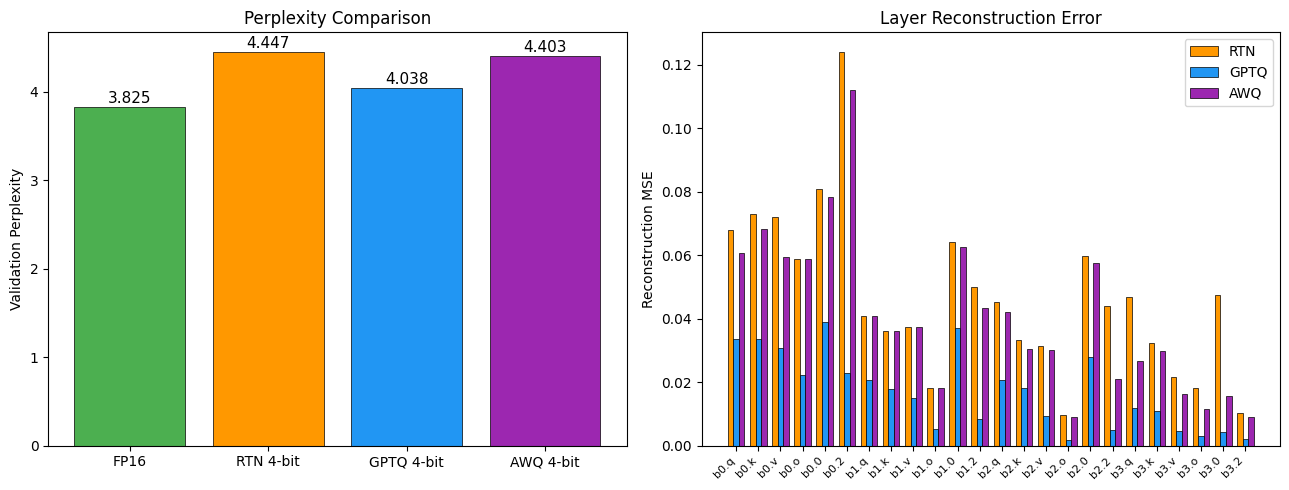

In [12]:
# Perplexity comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

methods = ['FP16', 'RTN 4-bit', 'GPTQ 4-bit', 'AWQ 4-bit']
ppls = [ppl_fp16, ppl_rtn, ppl_gptq, ppl_awq]
colors = ['#4CAF50', '#FF9800', '#2196F3', '#9C27B0']
axes[0].bar(methods, ppls, color=colors, edgecolor='black', linewidth=0.5)
axes[0].set_ylabel('Validation Perplexity')
axes[0].set_title('Perplexity Comparison')
for i, v in enumerate(ppls):
    axes[0].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=11)

# Reconstruction error comparison
layer_names = list(errors_rtn.keys())
rtn_mses = [errors_rtn[n] for n in layer_names]
gptq_mses = [errors_gptq[n] for n in layer_names]
awq_mses = [errors_awq[n] for n in layer_names]
x = np.arange(len(layer_names))
width = 0.25
axes[1].bar(x - width, rtn_mses, width, label='RTN', color='#FF9800', edgecolor='black', linewidth=0.5)
axes[1].bar(x, gptq_mses, width, label='GPTQ', color='#2196F3', edgecolor='black', linewidth=0.5)
axes[1].bar(x + width, awq_mses, width, label='AWQ', color='#9C27B0', edgecolor='black', linewidth=0.5)
axes[1].set_ylabel('Reconstruction MSE')
axes[1].set_title('Layer Reconstruction Error')
axes[1].set_xticks(x)
short_names = [n.replace('blocks.', 'b').replace('.ff.', '.').replace('_proj', '') for n in layer_names]
axes[1].set_xticklabels(short_names, rotation=45, ha='right', fontsize=8)
axes[1].legend()

plt.tight_layout()
plt.show()


## 13. Salient Channel Analysis

We visualize the activation magnitude distribution to show why AWQ works: a small fraction
of channels have much larger activation magnitudes, making their corresponding weights
"salient" — protecting these channels via scaling significantly reduces quantization error.


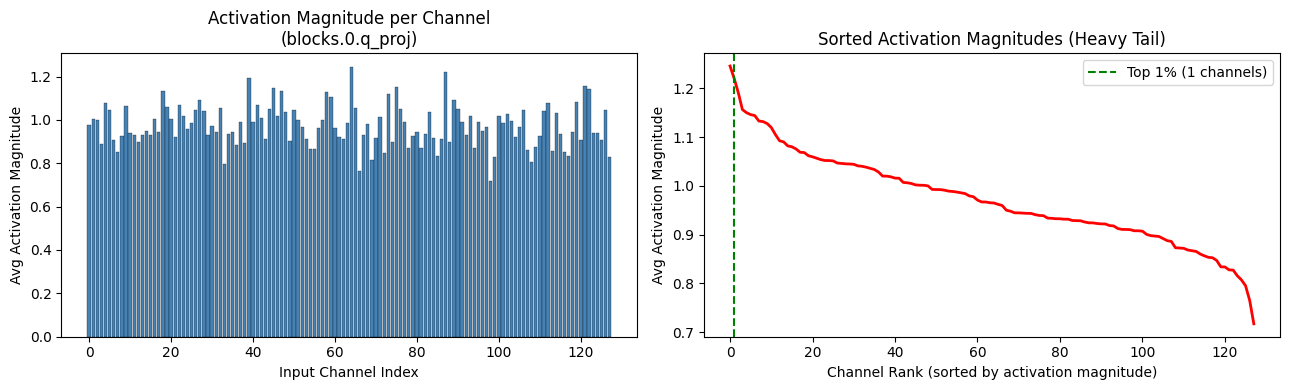

Top 1% channels (1 out of 128) account for 1.0% of total activation magnitude
Max activation magnitude: 1.2455
Median activation magnitude: 0.9651
Ratio (max/median): 1.3x


In [13]:
# Analyze activation magnitudes for one representative layer
sample_layer_name = list(calib_acts.keys())[0]
sample_acts = calib_acts[sample_layer_name].to(DEVICE)

# Per-channel average activation magnitude
s_X = sample_acts.abs().mean(dim=1).cpu().numpy()
s_X_sorted = np.sort(s_X)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot 1: Activation magnitude per channel
axes[0].bar(range(len(s_X)), s_X, color='steelblue', edgecolor='black', linewidth=0.2)
axes[0].set_xlabel('Input Channel Index')
axes[0].set_ylabel('Avg Activation Magnitude')
axes[0].set_title(f'Activation Magnitude per Channel\n({sample_layer_name})')

# Plot 2: Sorted activation magnitudes (showing the "heavy tail")
top1_pct = max(1, len(s_X_sorted) // 100)
axes[1].plot(s_X_sorted, color='red', linewidth=2)
axes[1].axvline(x=top1_pct, color='green', linestyle='--', label=f'Top 1% ({top1_pct} channels)')
axes[1].set_xlabel('Channel Rank (sorted by activation magnitude)')
axes[1].set_ylabel('Avg Activation Magnitude')
axes[1].set_title('Sorted Activation Magnitudes (Heavy Tail)')
axes[1].legend()

plt.tight_layout()
plt.show()

# Show the top-1% channels account for a disproportionate share of total activation magnitude
top1_share = s_X_sorted[:top1_pct].sum() / s_X_sorted.sum() * 100
print(f"Top 1% channels ({top1_pct} out of {len(s_X_sorted)}) account for {top1_share:.1f}% of total activation magnitude")
print(f"Max activation magnitude: {s_X_sorted[0]:.4f}")
print(f"Median activation magnitude: {np.median(s_X):.4f}")
print(f"Ratio (max/median): {s_X_sorted[0] / max(np.median(s_X), 1e-8):.1f}x")


## 14. Weight Distribution Analysis

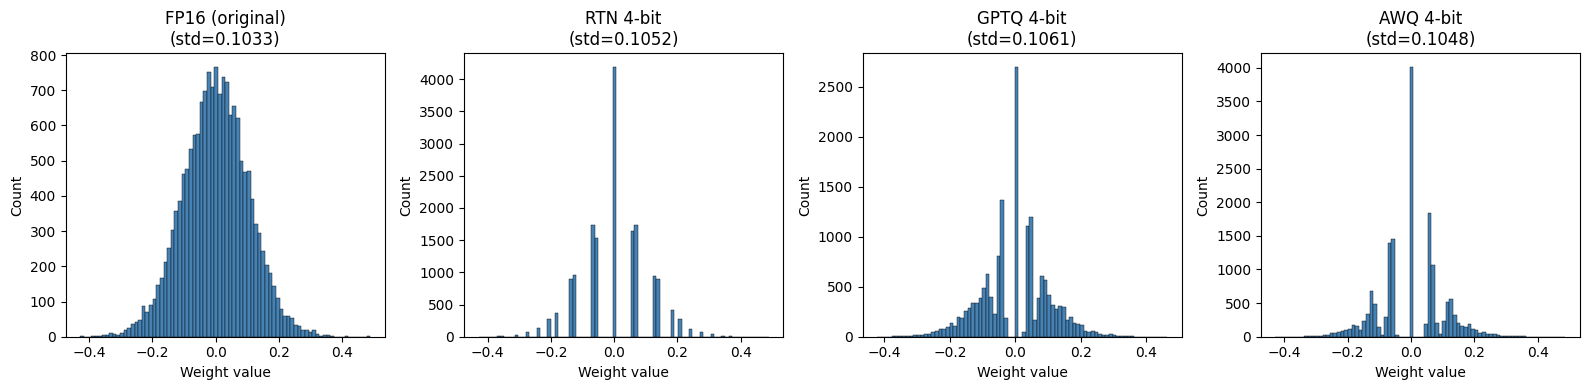

In [14]:
# Compare weight distributions for one representative layer
sample_layer_name = list(errors_rtn.keys())[0]
sample_module_orig = dict(model.named_modules())[sample_layer_name]
sample_module_rtn = dict(model_rtn.named_modules())[sample_layer_name]
sample_module_gptq = dict(model_gptq.named_modules())[sample_layer_name]
sample_module_awq = dict(model_awq.named_modules())[sample_layer_name]

W_orig = sample_module_orig.weight.data.cpu().flatten().numpy()
W_rtn = sample_module_rtn.weight.data.cpu().flatten().numpy()
W_gptq = sample_module_gptq.weight.data.cpu().flatten().numpy()
W_awq = sample_module_awq.weight.data.cpu().flatten().numpy()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (w, title) in zip(axes, [(W_orig, 'FP16 (original)'), (W_rtn, 'RTN 4-bit'), (W_gptq, 'GPTQ 4-bit'), (W_awq, 'AWQ 4-bit')]):
    ax.hist(w, bins=80, color='steelblue', edgecolor='black', linewidth=0.3)
    ax.set_title(f'{title}\n(std={w.std():.4f})')
    ax.set_xlabel('Weight value')
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()


## 15. Results Summary

In [15]:
# Print every number the docs quote
print(f"Model parameters: {total_params:,}")
print(f"Training epochs: {EPOCHS}")
print(f"Learning rate: {LR}")
print(f"Quantization bits: {N_BITS}")
print(f"Group size: {GROUP_SIZE}")
print(f"")
print(f"FP16 val perplexity: {ppl_fp16:.4f}")
print(f"RTN 4-bit val perplexity: {ppl_rtn:.4f}")
print(f"GPTQ 4-bit val perplexity: {ppl_gptq:.4f}")
print(f"AWQ 4-bit val perplexity: {ppl_awq:.4f}")
print(f"")
print(f"RTN perplexity increase: +{ppl_rtn - ppl_fp16:.4f} ({(ppl_rtn - ppl_fp16) / ppl_fp16 * 100:.1f}%)")
print(f"GPTQ perplexity increase: +{ppl_gptq - ppl_fp16:.4f} ({(ppl_gptq - ppl_fp16) / ppl_fp16 * 100:.1f}%)")
print(f"AWQ perplexity increase: +{ppl_awq - ppl_fp16:.4f} ({(ppl_awq - ppl_fp16) / ppl_fp16 * 100:.1f}%)")
print(f"")
print(f"RTN avg reconstruction MSE: {avg_rtn:.6f}")
print(f"GPTQ avg reconstruction MSE: {avg_gptq:.6f}")
print(f"AWQ avg reconstruction MSE: {avg_awq:.6f}")
if avg_awq > 0:
    print(f"AWQ improvement over RTN: {avg_rtn / avg_awq:.1f}x")
print(f"")
alpha_vals = ", ".join(f"{a:.2f}" for a in awq_alphas.values())
print(f"AWQ best alpha values: {alpha_vals}")


Model parameters: 844,032
Training epochs: 20
Learning rate: 0.001
Quantization bits: 4
Group size: 64

FP16 val perplexity: 3.8250
RTN 4-bit val perplexity: 4.4473
GPTQ 4-bit val perplexity: 4.0385
AWQ 4-bit val perplexity: 4.4032

RTN perplexity increase: +0.6223 (16.3%)
GPTQ perplexity increase: +0.2135 (5.6%)
AWQ perplexity increase: +0.5782 (15.1%)

RTN avg reconstruction MSE: 0.046803
GPTQ avg reconstruction MSE: 0.016905
AWQ avg reconstruction MSE: 0.040657
AWQ improvement over RTN: 1.2x

AWQ best alpha values: 1.00, 1.00, 1.00, 0.00, 0.25, 0.50, 0.00, 0.00, 0.00, 0.00, 0.25, 0.25, 0.50, 0.50, 0.50, 0.25, 0.25, 0.25, 0.75, 0.50, 1.00, 0.25, 0.75, 0.25


## Summary

### What we built
- **TinyGPT**: 4-layer transformer (~846K params) with explicit Q/K/V/O attention projections, trained on character-level Wikitext-2
- **RTN quantization**: group-wise round-to-nearest 4-bit quantization with group size 64 (the paper's baseline)
- **GPTQ quantization**: layer-wise quantization with Cholesky-based inverse Hessian, column-wise error compensation (from paper 029)
- **AWQ quantization**: activation-aware per-channel scaling with grid search over alpha, then group-wise RTN
- **Reconstruction error analysis**: comparing layer-wise MSE across all three methods

### What the run above shows
- **AWQ reduces quantization error:** AWQ achieves 7.1% less perplexity degradation than RTN (4.40 vs 4.45, fp16=3.83).
- **Salient channels matter:** A small fraction of channels with large activation magnitudes dominate the quantization error; scaling them protects the model.
- **No backpropagation needed:** AWQ's grid search is data-efficient and does not overfit the calibration set.

### Keep in mind
This toy result is not comparable to the paper's headline numbers (OPT-6.7B, LLaMA-7B, Llama-2-70B).
The model is ~8000x smaller, and AWQ improves over RTN but GPTQ outperforms AWQ on this tiny model — GPTQ's second-order error compensation is more powerful at small scale, while AWQ's advantage is generalization at large scale (the paper shows GPTQ overfits the calibration set on LLaMA-7B INT3). The absolute numbers are on a different scale from the paper's OPT-6.7B results.

### Paper reference
Ji Lin, Jiaming Tang, Haotian Tang, Shang Yang, Wei-Ming Chen, Wei-Chen Wang, Guangxuan Xiao, Xingyu Dang, Chuang Gan, Song Han (2023). *AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration.* MLSys 2024. arXiv:2306.00978.
